# Fit di riferimento e posizioni ACU

Origine: `~/juno/src/graph2.ipynb`.

Copia organizzata per la consultazione: le celle eseguibili e gli output originali sono conservati. I titoli aggiunti sono celle Markdown; i risultati salvati non sono stati ricalcolati. Eseguire dalla cartella di questo notebook. I dati ROOT esterni e gli eventuali problemi già presenti sono descritti in `docs/DATI_E_PERCORSI.md` nella radice del repository.


## Caricamento del fit di riferimento: run 14383


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import uproot
from scipy.special import erfc


ROOT_PATH = Path.home() / "juno/src/fit_run_14383.root"
OUTPUT_DIR = Path.home() / "Desktop/Tesi/output/fit_riferimento_17100"
BIN_ID = 40


def exp_gauss(t, area, mu, sigma, tau):
    """Stessa funzione di graph.ipynb, incluso il ramo asintotico."""
    t = np.asarray(t, dtype=float)
    if sigma <= 0 or tau <= 0:
        raise ValueError("sigma e tau devono essere positivi")
    a = (mu + sigma * sigma / tau - t) / (np.sqrt(2.0) * sigma)
    exponent = (mu - t) / tau + sigma * sigma / (2.0 * tau * tau)
    y = np.empty_like(t)
    mask = a > 20.0
    u = 1.0 / (2.0 * a[mask] ** 2)
    scaled_erfc = (1.0 - u + 3.0 * u**2 - 15.0 * u**3 + 105.0 * u**4) / (
        np.sqrt(np.pi) * a[mask]
    )
    y[mask] = (
        area / (2.0 * tau)
        * np.exp(-0.5 * ((t[mask] - mu) / sigma) ** 2)
        * scaled_erfc
    )
    y[~mask] = area / (2.0 * tau) * np.exp(exponent[~mask]) * erfc(a[~mask])
    return y


with uproot.open(ROOT_PATH) as root_file:
    fits = root_file["fit_summary"].arrays(library="np")
    rows = np.flatnonzero(fits["bin_id"] == BIN_ID)
    if len(rows) != 1:
        raise ValueError("Il file deve contenere un solo riferimento con bin_id = 40")
    row = int(rows[0])
    histogram = root_file[f"h_{BIN_ID}"]
    counts, edges = histogram.to_numpy(flow=False)
    errors = histogram.errors(flow=False)

assert row == 40  # Corrisponde proprio agli elementi [40] del notebook.
assert int(fits["run"][row]) == 14383
assert np.isclose(fits["source_z"][row], 17100.0)
assert bool(fits["accepted"][row]) and bool(fits["root_valid"][row])
assert int(fits["status"][row]) == 0

centers = (edges[:-1] + edges[1:]) / 2.0
# Normalizzazione identica ad area2 nella cella di confronto del notebook.
area = np.sum(counts * np.diff(edges))
fit_min, fit_max = float(fits["fit_min"][row]), float(fits["fit_max"][row])
xx = np.linspace(fit_min, fit_max, 1500)
C1, mu, sigma, tau1, C2, tau2, background = fits["params"][row]

component1 = exp_gauss(xx, C1, mu, sigma, tau1) / area
component2 = exp_gauss(xx, C2, mu, sigma, tau2) / area
constant = np.full_like(xx, background / area)
total = component1 + component2 + constant
assert np.all(np.isfinite(total))
assert np.isclose(np.sum((counts / area) * np.diff(edges)), 1.0)

# I nomi veloce/lenta seguono le costanti temporali, anche se l'ordine cambia.
if tau1 <= tau2:
    fast, slow = component1, component2
else:
    fast, slow = component2, component1



## Componenti del fit dei tempi residui


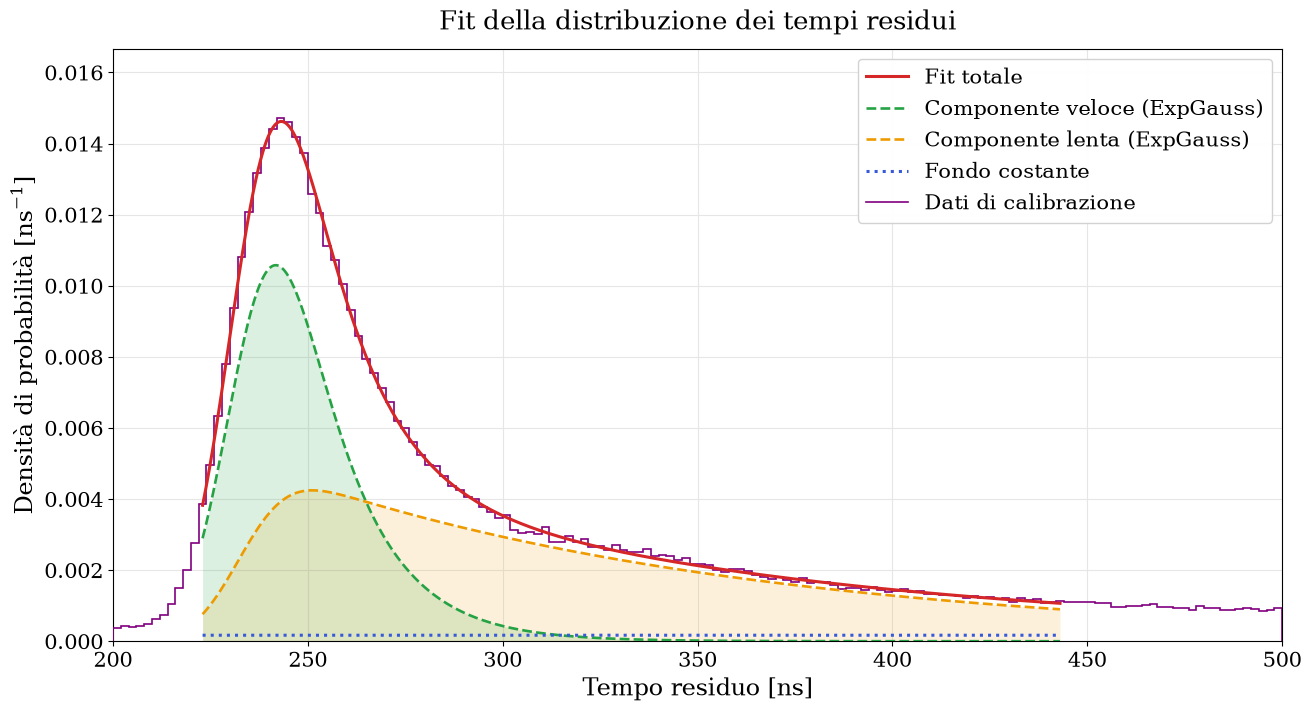

In [16]:
with plt.rc_context({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 19,
    "legend.fontsize": 15,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):


    fig, ax = plt.subplots(figsize=(13, 7), layout="constrained")
    ax.set_axisbelow(True)
    ax.grid(color="0.90", linewidth=0.8)

    # Le aree non sono impilate: mostrano le singole funzioni da sommare.
    ax.fill_between(xx, fast, color="#25a244", alpha=0.16, linewidth=0)
    ax.fill_between(xx, slow, color="#ed9b00", alpha=0.14, linewidth=0)
    line_total, = ax.plot(xx, total, color="#d62728", linewidth=2.2,
                          label="Fit totale", zorder=5)
    line_fast, = ax.plot(xx, fast, color="#25a244", linestyle="--", linewidth=1.9,
                         label="Componente veloce (ExpGauss)", zorder=4)
    line_slow, = ax.plot(xx, slow, color="#ed9b00", linestyle="--", linewidth=1.9,
                         label="Componente lenta (ExpGauss)", zorder=4)
    line_constant, = ax.plot(xx, constant, color="#365ad9", linestyle=":", linewidth=2.2,
                             label="Fondo costante", zorder=4)
    # data = ax.errorbar(centers, counts / area, yerr=errors / area,
    #                    fmt="o", markersize=2.7, color="0.18", ecolor="0.45",
    #                    elinewidth=0.75, capsize=0, label="Dati di riferimento",
    #                    zorder=3)
    data = ax.stairs(
    counts / area,
    edges,
    color="purple",
    linewidth=1.2,
    label="Dati di calibrazione",
    zorder=3,
)
    ax.set_title(
        "Fit della distribuzione dei tempi residui",
        pad=14
    )
    ax.set_xlabel("Tempo residuo [ns]")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_ylim(0, 1.12 * np.max((counts + errors) / area))
    ax.set_ylabel(r"Densità di probabilità [$\mathrm{ns}^{-1}$]")
    ax.legend(handles=[line_total, line_fast, line_slow, line_constant, data],
              loc="upper right", framealpha=0.97, edgecolor="0.82")

plt.show()

## Posizioni di calibrazione ACU nel rivelatore


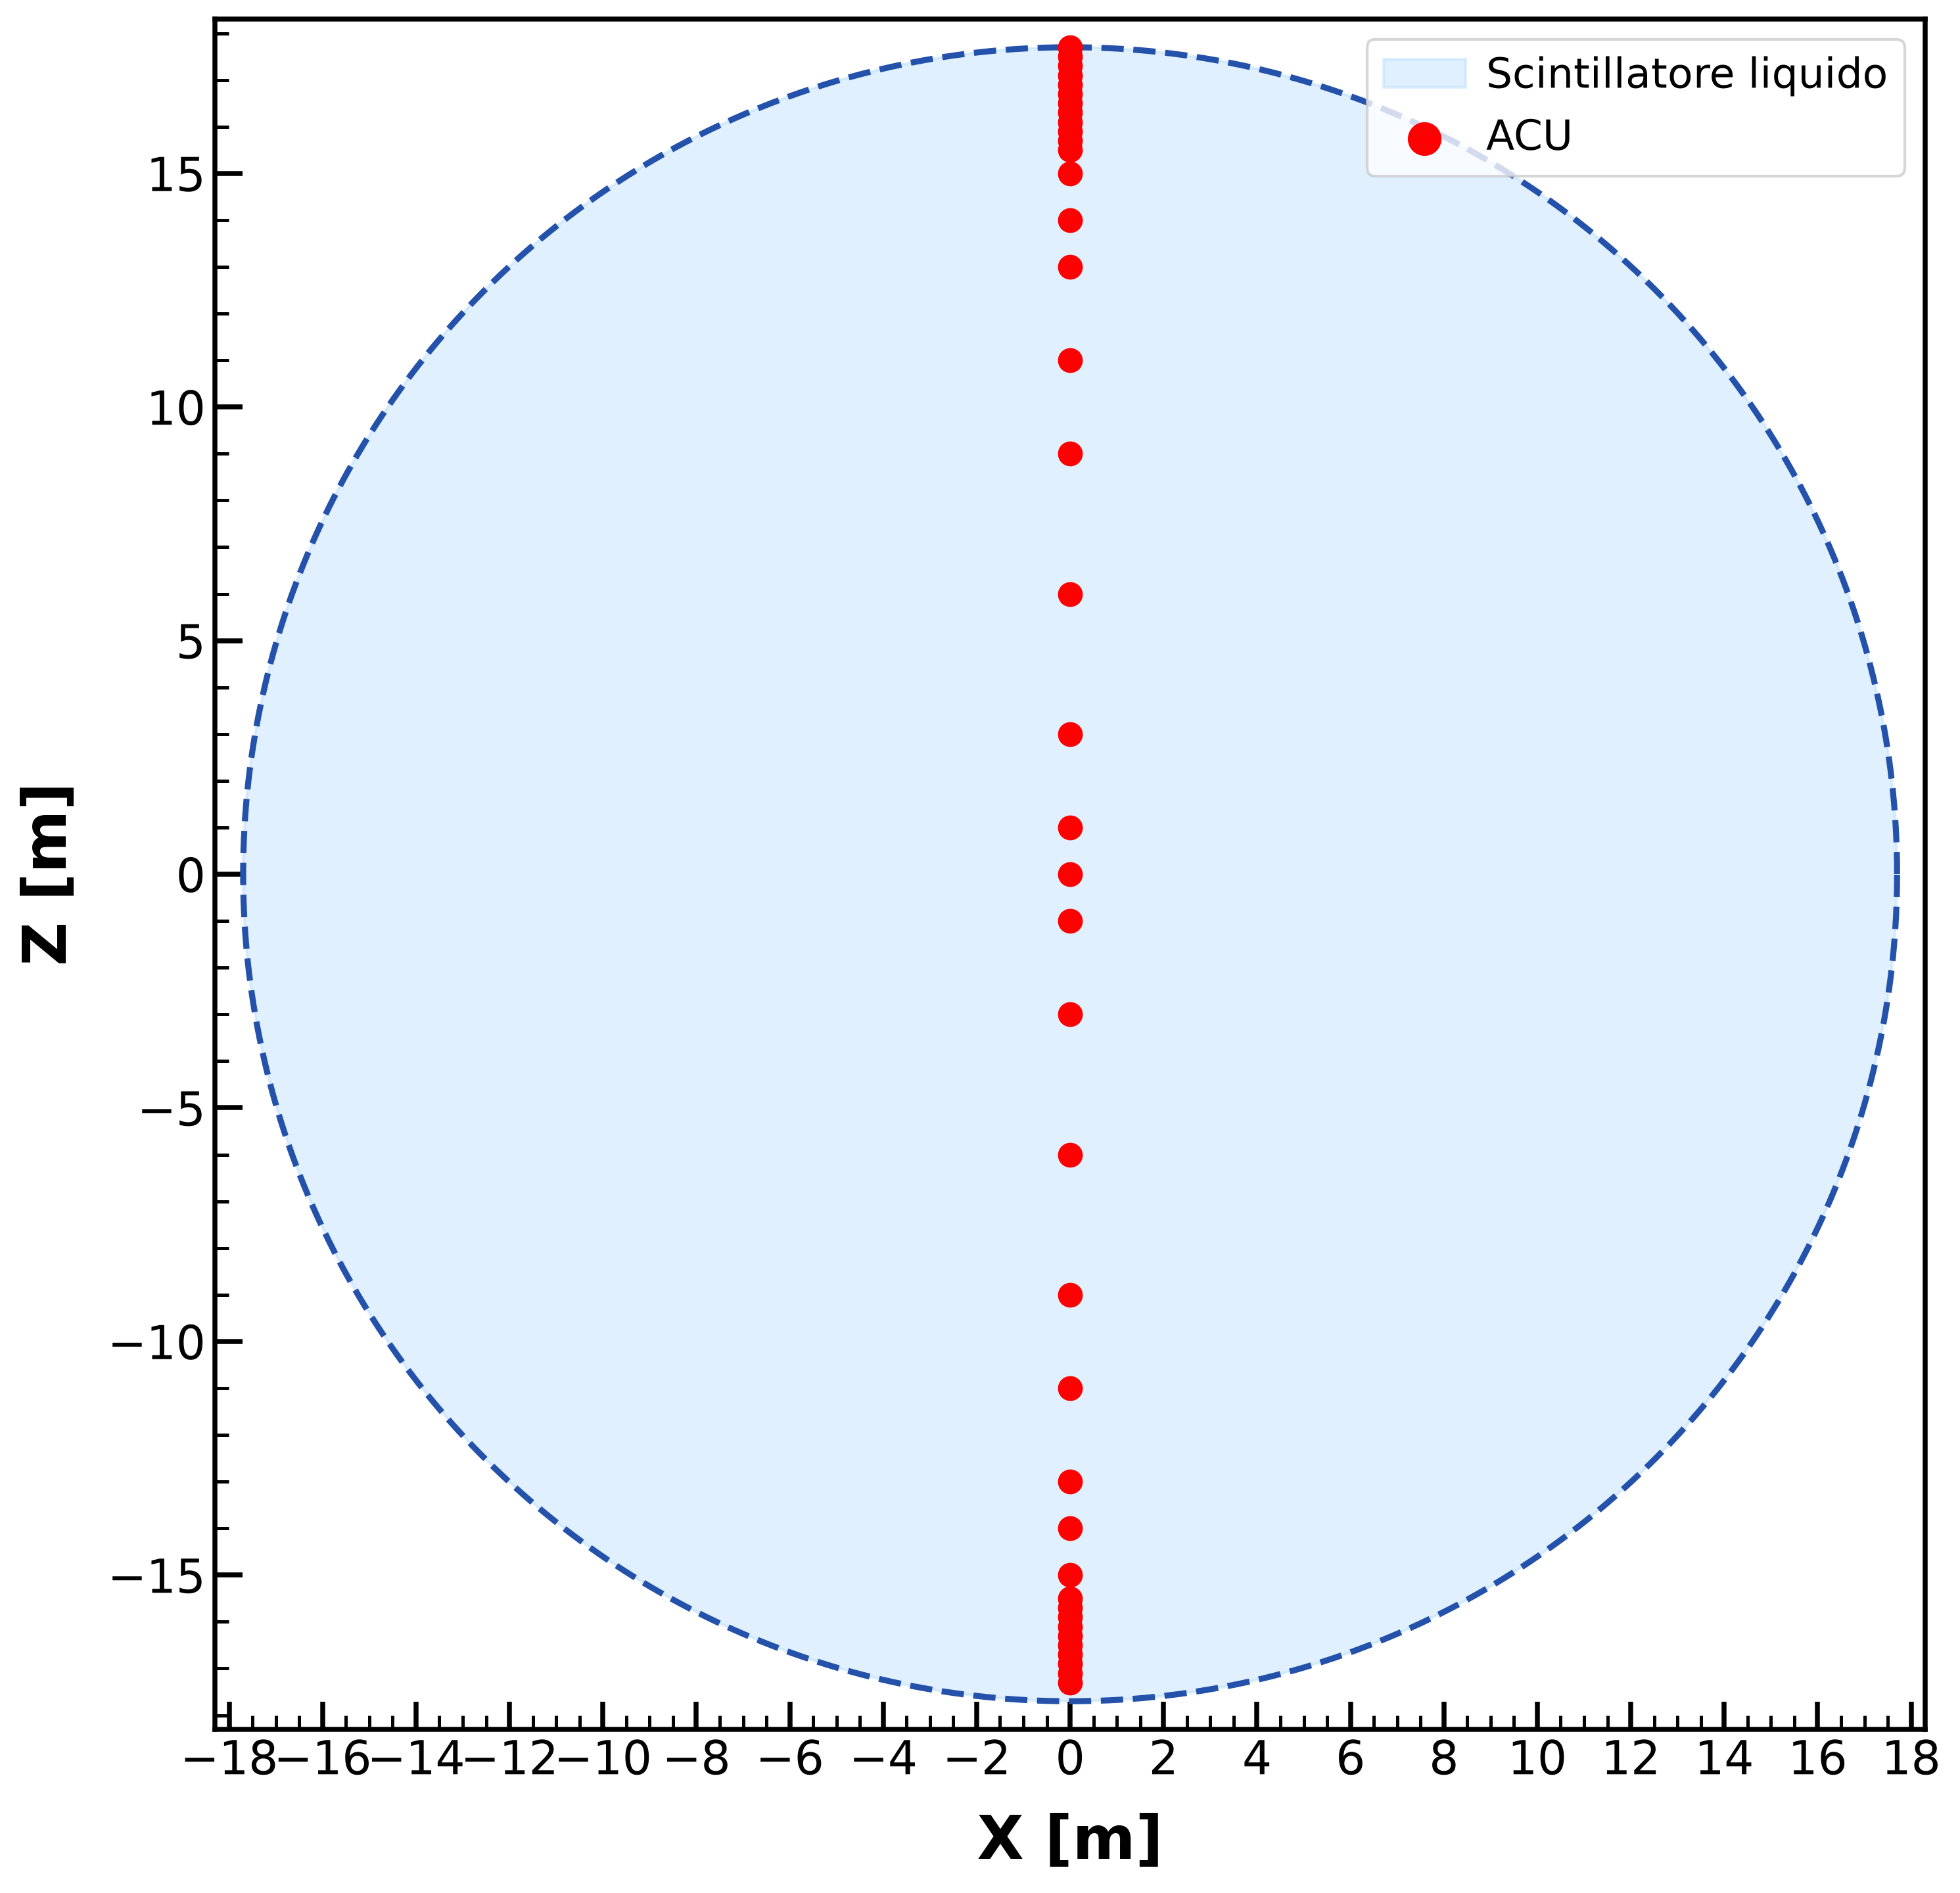

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# Caricamento delle posizioni di calibrazione (seconda colonna in mm -> m)
data = np.loadtxt('output_con_picchi.txt')
z_positions_m = data[:, 1] / 1000.0
x_positions_m = np.zeros_like(z_positions_m)

# Cerchio del bordo del rivelatore (R = 17.7 m)
R = 17.7
theta = np.linspace(0, np.pi * 2, 500)
x_arc = R * np.cos(theta)
z_arc = R * np.sin(theta)

# Creazione della figura
fig, ax = plt.subplots(figsize=(10, 10), dpi=300)

# Riempimento per lo "Scintillatore liquido"
ax.fill(x_arc, z_arc, color="#a8d5ff", alpha=0.35, label='Scintillatore liquido', zorder=1)

# Profilo tratteggiato del bordo
ax.plot(x_arc, z_arc, linestyle='--', color="#2451aa", linewidth=2.2, zorder=2)

# Punti rossi sull'asse verticale (ACU)
ax.scatter(x_positions_m, z_positions_m, color='red', s=65, label='ACU', zorder=3)

# Limiti, proporzioni ed etichette degli assi ingrandite per slide
ax.set_xlim(-18.3, 18.3)
ax.set_ylim(-18.3, 18.3)
ax.set_aspect('equal')
ax.set_xlabel('X [m]', fontsize=22, fontweight='bold', labelpad=10)
ax.set_ylabel('Z [m]', fontsize=22, fontweight='bold', labelpad=10)

# Spessore della cornice
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

# Configurazione dei tick
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.xaxis.set_minor_locator(MultipleLocator(0.5))
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_minor_locator(MultipleLocator(1))

# Dimensione e spessore dei tick e dei numeri
ax.tick_params(axis='both', which='major', direction='in', length=10, width=1.8, labelsize=17)
ax.tick_params(axis='both', which='minor', direction='in', length=5, width=1.2)

# Legenda con testo grande
ax.legend(loc='upper right', fontsize=15, handletextpad=0.5, markerscale=1.4)

plt.tight_layout()
plt.savefig('calibrazione_ACU.pdf')
plt.savefig('calibrazione_ACU.png', dpi=300)
plt.show()